# EEE 117 unit 1, solved two ways: SymPy and Lean

| Topic | SymPy (`dgs.eee117_circuits`) | Lean (`lean/EEE117Circuits.lean`) |
|---|---|---|
| Voltage, current, power, energy; Ohm's law | `ohm`, `power_forms` | P = I²R = V²/R |
| Sources, polarity, absorbed power | `Circuit.element_table`, Tellegen | series power balance |
| Series and parallel | `series`, `parallel` | R₁R₂/(R₁+R₂) < R₁ |
| Voltage and current dividers | `voltage_divider`, `current_divider` | the parts add back to the whole |
| Measuring resistance: Wheatstone bridge | `wheatstone_output`, `wheatstone_unknown` | balance ⇒ zero output |
| Delta-to-wye | `delta_to_wye`, `wye_to_delta` | terminal equivalence |
| Node-voltage method | `Circuit` (KCL) | |
| Mesh-current method | `Mesh` (KVL) | |
| Operational amplifiers | `inverting_amp`, `noninverting_amp`, `summing_amp` | the two gain formulas |
| Binary | `r2r_dac` (a 3-bit DAC) | ladder output = binary weights |

**SymPy** gives exact algebra. **Lean** is machine-checked and counts only if `%lean_check`
(the last section) reports VERIFIED. Work each problem by hand first, then compare.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
import pandas as pd, sympy as sp
from IPython.display import display, Markdown
sp.init_printing(use_unicode=True)
from dgs import eee117_circuits as E
from dgs.field_circuits import Circuit
R1, R2, R3, R4, Rf, Rin, Vs, Is = sp.symbols("R_1 R_2 R_3 R_4 R_f R_in V_s I_s", positive=True)

In [2]:
%load_ext dgs.lean_magic
%lean_reset

Lean cells cleared.


In [3]:
%%lean header
/-
EEE 117 resistive circuits: the machine-checkable algebra. Lean 4 + Mathlib.
Companion to notebooks/eee117_circuits_sympy_lean.ipynb and dgs/eee117_circuits.py.

What is proved here (resistances are positive reals):
  1. Ohm's law and power: P = V I with V = I R gives P = I^2 R and P = V^2 / R
  2. Series and parallel: two resistors in parallel equal R1 R2 / (R1 + R2), less than either one
  3. Voltage divider: the two drops add to Vs; current divider: branch currents add to Is
  4. Wheatstone bridge: R1 R4 = R2 R3 implies the bridge output is zero
  5. Delta-to-wye: the wye seen between terminals 1 and 2 equals R12 parallel (R23 + R31)
  6. Ideal op-amps: inverting gain -Rf/Rin, non-inverting gain 1 + Rf/Rg
  7. Energy: in a series circuit the source power equals the resistor powers (Tellegen)
  8. Binary: a 3-bit R-2R ladder output is Vref (4 b2 + 2 b1 + b0) / 8

Check with (from a Lake project that depends on Mathlib):
    lake env lean EEE117Circuits.lean
-/
import Mathlib.Data.Real.Basic
import Mathlib.Tactic.Ring
import Mathlib.Tactic.Linarith
import Mathlib.Tactic.LinearCombination
import Mathlib.Tactic.FieldSimp
import Mathlib.Tactic.Positivity

namespace EEE117

**Lean cell `header`** (collected; compiled by `%lean_check`)
```lean
/-
EEE 117 resistive circuits: the machine-checkable algebra. Lean 4 + Mathlib.
Companion to notebooks/eee117_circuits_sympy_lean.ipynb and dgs/eee117_circuits.py.

What is proved here (resistances are positive reals):
  1. Ohm's law and power: P = V I with V = I R gives P = I^2 R and P = V^2 / R
  2. Series and parallel: two resistors in parallel equal R1 R2 / (R1 + R2), less than either one
  3. Voltage divider: the two drops add to Vs; current divider: branch currents add to Is
  4. Wheatstone bridge: R1 R4 = R2 R3 implies the bridge output is zero
  5. Delta-to-wye: the wye seen between terminals 1 and 2 equals R12 parallel (R23 + R31)
  6. Ideal op-amps: inverting gain -Rf/Rin, non-inverting gain 1 + Rf/Rg
  7. Energy: in a series circuit the source power equals the resistor powers (Tellegen)
  8. Binary: a 3-bit R-2R ladder output is Vref (4 b2 + 2 b1 + b0) / 8

Check with (from a Lake project that depends on Mathlib):
    lake env lean EEE117Circuits.lean
-/
import Mathlib.Data.Real.Basic
import Mathlib.Tactic.Ring
import Mathlib.Tactic.Linarith
import Mathlib.Tactic.LinearCombination
import Mathlib.Tactic.FieldSimp
import Mathlib.Tactic.Positivity

namespace EEE117
```

## 1. Voltage, current, power, and energy; Ohm's law

V = IR. Power is the rate of energy, p = vi in watts, and energy is w = ∫p dt in joules.
With the passive sign convention (current enters the + terminal), p > 0 means *absorbed*.

In [4]:
display(E.ohm(V=12, R=4))
V, I, R = sp.symbols("V I R", positive=True)
display(E.power_forms(I * R, I, R))

{'V': 12, 'I': 3, 'R': 4, 'P': 36}

{'VI': I**2*R, 'I2R': I**2*R, 'V2/R': I**2*R}

In [5]:
%%lean ohm
/-! ## 1. Ohm's law and power -/

theorem power_I2R (V I R : ℝ) (h : V = I * R) : V * I = I ^ 2 * R := by
  rw [h]; ring

theorem power_V2R (V I R : ℝ) (hR : R ≠ 0) (h : V = I * R) : V * I = V ^ 2 / R := by
  rw [h]; field_simp

**Lean cell `ohm`** (collected; compiled by `%lean_check`)
```lean
/-! ## 1. Ohm's law and power -/

theorem power_I2R (V I R : ℝ) (h : V = I * R) : V * I = I ^ 2 * R := by
  rw [h]; ring

theorem power_V2R (V I R : ℝ) (hR : R ≠ 0) (h : V = I * R) : V * I = V ^ 2 / R := by
  rw [h]; field_simp
```

## 2. Series and parallel

In [6]:
display(sp.Eq(sp.Symbol("R_series"), E.series(R1, R2, R3)), sp.Eq(sp.Symbol("R_parallel"), E.parallel(R1, R2)))
print("6 ohm || 3 ohm =", E.parallel(6, 3), "ohm;  1 + 2 + 3 =", E.series(1, 2, 3), "ohm")

6 ohm || 3 ohm = 2 ohm;  1 + 2 + 3 = 6 ohm


In [7]:
%%lean series_parallel
/-! ## 2. Series and parallel -/

theorem parallel_two (R1 R2 : ℝ) (h1 : 0 < R1) (h2 : 0 < R2) :
    1 / (1 / R1 + 1 / R2) = R1 * R2 / (R1 + R2) := by
  field_simp
  ring

theorem parallel_less (R1 R2 : ℝ) (h1 : 0 < R1) (h2 : 0 < R2) :
    R1 * R2 / (R1 + R2) < R1 := by
  rw [div_lt_iff₀ (by positivity)]
  nlinarith

**Lean cell `series_parallel`** (collected; compiled by `%lean_check`)
```lean
/-! ## 2. Series and parallel -/

theorem parallel_two (R1 R2 : ℝ) (h1 : 0 < R1) (h2 : 0 < R2) :
    1 / (1 / R1 + 1 / R2) = R1 * R2 / (R1 + R2) := by
  field_simp
  ring

theorem parallel_less (R1 R2 : ℝ) (h1 : 0 < R1) (h2 : 0 < R2) :
    R1 * R2 / (R1 + R2) < R1 := by
  rw [div_lt_iff₀ (by positivity)]
  nlinarith
```

## 3. Voltage divider and current divider

In [8]:
display(sp.Eq(sp.Symbol("v_2"), E.voltage_divider(Vs, R2, R1)), sp.Eq(sp.Symbol("i_1"), E.current_divider(Is, R1, R2)))
print("10 V across 3 ohm + 2 ohm: the 3 ohm sees", E.voltage_divider(10, 3, 2), "V")
print("9 A into 3 ohm || 6 ohm: the 3 ohm takes", E.current_divider(9, 3, 6), "A (the SMALLER resistor takes MORE current)")

10 V across 3 ohm + 2 ohm: the 3 ohm sees 6 V
9 A into 3 ohm || 6 ohm: the 3 ohm takes 6 A (the SMALLER resistor takes MORE current)


In [9]:
%%lean dividers
/-! ## 3. Dividers -/

theorem voltage_divider_sum (Vs R1 R2 : ℝ) (h1 : 0 < R1) (h2 : 0 < R2) :
    Vs * R1 / (R1 + R2) + Vs * R2 / (R1 + R2) = Vs := by
  field_simp

theorem current_divider_sum (Is R1 R2 : ℝ) (h1 : 0 < R1) (h2 : 0 < R2) :
    Is * R2 / (R1 + R2) + Is * R1 / (R1 + R2) = Is := by
  field_simp; ring

/-- Both branches of a current divider see the same voltage. -/
theorem current_divider_same_voltage (Is R1 R2 : ℝ) :
    (Is * R2 / (R1 + R2)) * R1 = (Is * R1 / (R1 + R2)) * R2 := by
  ring

**Lean cell `dividers`** (collected; compiled by `%lean_check`)
```lean
/-! ## 3. Dividers -/

theorem voltage_divider_sum (Vs R1 R2 : ℝ) (h1 : 0 < R1) (h2 : 0 < R2) :
    Vs * R1 / (R1 + R2) + Vs * R2 / (R1 + R2) = Vs := by
  field_simp

theorem current_divider_sum (Is R1 R2 : ℝ) (h1 : 0 < R1) (h2 : 0 < R2) :
    Is * R2 / (R1 + R2) + Is * R1 / (R1 + R2) = Is := by
  field_simp; ring

/-- Both branches of a current divider see the same voltage. -/
theorem current_divider_same_voltage (Is R1 R2 : ℝ) :
    (Is * R2 / (R1 + R2)) * R1 = (Is * R1 / (R1 + R2)) * R2 := by
  ring
```

## 4. Measuring resistance: the Wheatstone bridge

Adjust the known resistors until the meter between the two midpoints reads zero. Then
R₁R₄ = R₂R₃, so the unknown is R₄ = R₂R₃/R₁. At balance no current flows through the meter, so
its own resistance doesn't matter.

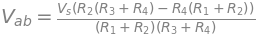

R1 = 100, R2 = 200, R3 = 300 at balance -> unknown R4 = 600 ohm


In [10]:
display(sp.Eq(sp.Symbol("V_ab"), E.wheatstone_output(Vs, R1, R2, R3, R4)))
print("R1 = 100, R2 = 200, R3 = 300 at balance -> unknown R4 =", E.wheatstone_unknown(100, 200, 300), "ohm")

In [11]:
%%lean wheatstone
/-! ## 4. Wheatstone bridge -/

theorem wheatstone_balance (Vs R1 R2 R3 R4 : ℝ) (h1 : 0 < R1) (h2 : 0 < R2) (h3 : 0 < R3)
    (h4 : 0 < R4) (hbal : R1 * R4 = R2 * R3) :
    Vs * R2 / (R1 + R2) - Vs * R4 / (R3 + R4) = 0 := by
  have hA : R1 + R2 ≠ 0 := by positivity
  have hB : R3 + R4 ≠ 0 := by positivity
  rw [sub_eq_zero, div_eq_div_iff hA hB]
  linear_combination Vs * hbal * (-1)

**Lean cell `wheatstone`** (collected; compiled by `%lean_check`)
```lean
/-! ## 4. Wheatstone bridge -/

theorem wheatstone_balance (Vs R1 R2 R3 R4 : ℝ) (h1 : 0 < R1) (h2 : 0 < R2) (h3 : 0 < R3)
    (h4 : 0 < R4) (hbal : R1 * R4 = R2 * R3) :
    Vs * R2 / (R1 + R2) - Vs * R4 / (R3 + R4) = 0 := by
  have hA : R1 + R2 ≠ 0 := by positivity
  have hB : R3 + R4 ≠ 0 := by positivity
  rw [sub_eq_zero, div_eq_div_iff hA hB]
  linear_combination Vs * hbal * (-1)
```

## 5. Delta-to-wye

In [12]:
y = E.delta_to_wye(R1, R2, R3)
display(dict(zip(["R_a", "R_b", "R_c"], y)))
print("round trip back to delta:", [sp.simplify(v) for v in E.wye_to_delta(*y)])
print("equal delta 30, 30, 30 -> wye", E.delta_to_wye(30, 30, 30), "(R_Y = R_delta / 3)")

{'R_a': R_1*R_3/(R_1 + R_2 + R_3),
 'R_b': R_1*R_2/(R_1 + R_2 + R_3),
 'R_c': R_2*R_3/(R_1 + R_2 + R_3)}

round trip back to delta: [R_1, R_2, R_3]
equal delta 30, 30, 30 -> wye (10, 10, 10) (R_Y = R_delta / 3)


In [13]:
%%lean delta_wye
/-! ## 5. Delta-to-wye -/

theorem delta_wye_terminals_12 (R12 R23 R31 : ℝ) (h1 : 0 < R12) (h2 : 0 < R23) (h3 : 0 < R31) :
    R12 * R31 / (R12 + R23 + R31) + R12 * R23 / (R12 + R23 + R31)
      = R12 * (R23 + R31) / (R12 + (R23 + R31)) := by
  rw [← add_assoc]
  field_simp
  ring

**Lean cell `delta_wye`** (collected; compiled by `%lean_check`)
```lean
/-! ## 5. Delta-to-wye -/

theorem delta_wye_terminals_12 (R12 R23 R31 : ℝ) (h1 : 0 < R12) (h2 : 0 < R23) (h3 : 0 < R31) :
    R12 * R31 / (R12 + R23 + R31) + R12 * R23 / (R12 + R23 + R31)
      = R12 * (R23 + R31) / (R12 + (R23 + R31)) := by
  rw [← add_assoc]
  field_simp
  ring
```

## 6. Node-voltage and mesh-current methods on the same circuit

A 10 V source and R₁ = 2 Ω feed a node b, which has R₂ = 4 Ω and R₃ = 4 Ω to ground.
- **Node-voltage:** one unknown (V_b), from KCL.
- **Mesh-current:** two unknowns (I_A, I_B), from KVL.

Same answer either way. Choose the method with fewer unknowns.

In [14]:
ckt = Circuit().V("Vs", "a", "0", 10).R("R1", "a", "b", 2).R("R2", "b", "0", 4).R("R3", "b", "0", 4)
print("NODE-VOLTAGE\n" + ckt.paper())
m = E.Mesh().V("Vs", 10, "A").R("R1", 2, "A").R("R2", 4, "A", "B").R("R3", 4, "B")
print("\nMESH-CURRENT\n" + m.paper())
A, b = m.matrix(); display(sp.Eq(sp.MatMul(A, sp.Matrix([sp.Symbol("I_A"), sp.Symbol("I_B")])), b))
print("check: V_b from mesh = I_R2 * 4 =", m.branch_current("R2") * 4, "  from node-voltage =", ckt.solve()[sp.Symbol("V_b")])
display(pd.DataFrame(ckt.element_table()))
print("Tellegen (sum of absorbed power):", ckt.tellegen())

NODE-VOLTAGE
1. Label every node; node 0 is ground: a, b
2. Unknowns: V_a, V_b, I_Vs
3. KCL (currents leaving each node = 0), and source constraints:
     I_Vs + V_a/2 - V_b/2 = 0
     -V_a/2 + V_b = 0
     V_a = 10
4. Write as A x = b and solve (substitution, Cramer, or row reduction).
     I_Vs = -5/2
     V_a = 10
     V_b = 5
5. Check: units, s -> 0 (capacitors open, inductors short), s -> oo.

MESH-CURRENT
1. Draw a clockwise current in each mesh: I_A, I_B
2. KVL around each mesh (resistor drops = source rises):
     6*I_A - 4*I_B = 10
     -4*I_A + 8*I_B = 0
3. Solve:
     I_A = 5/2
     I_B = 5/4


⎡6   -4⎤ ⎡I_A⎤   ⎡10⎤
⎢      ⎥⋅⎢   ⎥ = ⎢  ⎥
⎣-4  8 ⎦ ⎣I_B⎦   ⎣0 ⎦

check: V_b from mesh = I_R2 * 4 = 5   from node-voltage = 5


,element,kind,+ node,- node,v = V+ - V-,i (+ to - through it),p = v i (absorbed),role
0,Vs,V,a,0,10,-5/2,-25,delivers
1,R1,R,a,b,5,5/2,25/2,absorbs
2,R2,R,b,0,5,5/4,25/4,absorbs
3,R3,R,b,0,5,5/4,25/4,absorbs


Tellegen (sum of absorbed power): 0


## 7. Operational amplifiers

The ideal op-amp rules are: no current into the inputs, and V₊ = V₋ when there's negative feedback.
The node-voltage solver takes the op-amp's output current as one more unknown.

In [15]:
for name, fn in [("inverting", E.inverting_amp), ("non-inverting", E.noninverting_amp)]:
    ckt_oa, vout = fn(Rin, Rf)
    display(Markdown(f"**{name}**")); display(sp.Eq(sp.Symbol("V_out"), sp.factor(vout)))
    print("  Tellegen with the op-amp's supply included:", ckt_oa.tellegen())
_, vsum = E.summing_amp([1000, 2000], 4000, [1, 2])
print("summing amp, Rf = 4k, inputs 1 V via 1k and 2 V via 2k: V_out =", vsum, "V")

**inverting**

  Tellegen with the op-amp's supply included: 0


**non-inverting**

  Tellegen with the op-amp's supply included: 0
summing amp, Rf = 4k, inputs 1 V via 1k and 2 V via 2k: V_out = -8 V


In [16]:
%%lean opamps
/-! ## 6. Ideal op-amps -/

/-- Inverting: V- = 0 (virtual ground), KCL at V-: Vin/Rin + Vout/Rf = 0. -/
theorem inverting_gain (Vin Vout Rin Rf : ℝ) (hin : Rin ≠ 0) (hf : Rf ≠ 0)
    (kcl : Vin / Rin + Vout / Rf = 0) : Vout = -(Rf / Rin) * Vin := by
  field_simp at kcl ⊢
  linear_combination kcl

/-- Non-inverting: V- = Vin, KCL at V-: Vin/Rg + (Vin - Vout)/Rf = 0. -/
theorem noninverting_gain (Vin Vout Rg Rf : ℝ) (hg : Rg ≠ 0) (hf : Rf ≠ 0)
    (kcl : Vin / Rg + (Vin - Vout) / Rf = 0) : Vout = (1 + Rf / Rg) * Vin := by
  field_simp at kcl ⊢
  linear_combination -kcl

**Lean cell `opamps`** (collected; compiled by `%lean_check`)
```lean
/-! ## 6. Ideal op-amps -/

/-- Inverting: V- = 0 (virtual ground), KCL at V-: Vin/Rin + Vout/Rf = 0. -/
theorem inverting_gain (Vin Vout Rin Rf : ℝ) (hin : Rin ≠ 0) (hf : Rf ≠ 0)
    (kcl : Vin / Rin + Vout / Rf = 0) : Vout = -(Rf / Rin) * Vin := by
  field_simp at kcl ⊢
  linear_combination kcl

/-- Non-inverting: V- = Vin, KCL at V-: Vin/Rg + (Vin - Vout)/Rf = 0. -/
theorem noninverting_gain (Vin Vout Rg Rf : ℝ) (hg : Rg ≠ 0) (hf : Rf ≠ 0)
    (kcl : Vin / Rg + (Vin - Vout) / Rf = 0) : Vout = (1 + Rf / Rg) * Vin := by
  field_simp at kcl ⊢
  linear_combination -kcl
```

In [17]:
%%lean energy
/-! ## 7. Energy conservation -/

theorem series_power_balance (Vs I R1 R2 : ℝ) (h : Vs = I * (R1 + R2)) :
    Vs * I = I ^ 2 * R1 + I ^ 2 * R2 := by
  rw [h]; ring

**Lean cell `energy`** (collected; compiled by `%lean_check`)
```lean
/-! ## 7. Energy conservation -/

theorem series_power_balance (Vs I R1 R2 : ℝ) (h : Vs = I * (R1 + R2)) :
    Vs * I = I ^ 2 * R1 + I ^ 2 * R2 := by
  rw [h]; ring
```

## 8. Binary: a 3-bit R-2R ladder DAC

A computer-engineering bridge: switch each bit between 0 and V_ref, and the ladder outputs
V_ref × code / 2ⁿ. Here node-voltage analysis solves the full ladder for all 8 codes.

In [18]:
from itertools import product
rows = [("".join(map(str, b)), int("".join(map(str, b)), 2), E.r2r_dac(b, Vref=8)[1]) for b in product((0, 1), repeat=3)]
display(pd.DataFrame(rows, columns=["bits", "code", "V_out (Vref = 8 V)"]))

,bits,code,V_out (Vref = 8 V)
0,000,0,0
1,001,1,1
2,010,2,2
3,011,3,3
4,100,4,4
5,101,5,5
6,110,6,6
7,111,7,7


In [19]:
%%lean r2r
/-! ## 8. Binary R-2R ladder -/

theorem r2r_three_bit (Vref b2 b1 b0 : ℝ) :
    Vref * (b2 / 2 + b1 / 4 + b0 / 8) = Vref * (4 * b2 + 2 * b1 + b0) / 8 := by
  ring

**Lean cell `r2r`** (collected; compiled by `%lean_check`)
```lean
/-! ## 8. Binary R-2R ladder -/

theorem r2r_three_bit (Vref b2 b1 b0 : ℝ) :
    Vref * (b2 / 2 + b1 / 4 + b0 / 8) = Vref * (4 * b2 + 2 * b1 + b0) / 8 := by
  ring
```

## 9. Compile every Lean cell at once

In [20]:
%%lean footer
end EEE117

**Lean cell `footer`** (collected; compiled by `%lean_check`)
```lean
end EEE117
```

In [21]:
lean_result = %lean_check
from dgs.lean_magic import SESSION
display(pd.DataFrame({"Lean theorem": SESSION.last.theorems, "status": SESSION.last.status}))

Lean status: VERIFIED  (lake env lean exit 0, no errors, no sorry), 8 s


,Lean theorem,status
0,power_I2R,VERIFIED
1,power_V2R,VERIFIED
2,parallel_two,VERIFIED
3,parallel_less,VERIFIED
4,voltage_divider_sum,VERIFIED
5,current_divider_sum,VERIFIED
6,current_divider_same_voltage,VERIFIED
7,wheatstone_balance,VERIFIED
8,delta_wye_terminals_12,VERIFIED
9,inverting_gain,VERIFIED
